# HW09 - Single-balanced mixer comparison

Select **ECE6420 (Local)** and connect GlobalProtect for a fresh simulation. **Run All** sends the current parameter dictionary to the school Spectre worker, receives numerical traces, and renders figures here. The notebook kernel and PDF generation run locally.

The two circuits follow the supplied active 3-NMOS current-commutating topology and passive 2-NMOS switching topology. See the final report for exact device values, terminal connections, bias conditions, measurement conventions, and schematic reconstruction steps.

**Standalone Python baseline:** this notebook runs the earlier Python-generated-netlist campaign. Native schematic experiments must be run in ADE; use `01_cadence_gui_review.ipynb` to fetch and review their actual GUI results. This notebook writes only the separately named Python-baseline PDF.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys

_cwd = Path.cwd().resolve()
_candidates = [_cwd, _cwd / 'HW09', *_cwd.parents]
ROOT = next((p for p in _candidates if (p / 'lib/remote_bridge.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the HW09 project directory.')
if str(ROOT / 'lib') not in sys.path:
    sys.path.insert(0, str(ROOT / 'lib'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'simulation/matplotlib'))
from mixer import default_config
from remote_bridge import run_remote

EXECUTION_MODE = os.environ.get('HW09_EXECUTION_MODE', 'remote')
print('Local interpreter:', sys.executable)
print('Project:', ROOT)
print('Execution mode:', EXECUTION_MODE)
print('Kernel: ECE6420 (Local); Spectre runs over SSH independently of this kernel.')
%matplotlib inline

Local interpreter: /Users/jeonsang-eon/Gatech-ECE6420/HW09/.venv/bin/python
Project: /Users/jeonsang-eon/Gatech-ECE6420/HW09
Execution mode: remote
Kernel: ECE6420 (Local); Spectre runs over SSH independently of this kernel.


## Parameters

Start from the complete maintained configuration. Edit the dictionary below before running the next cell. Current Python values, including unsaved notebook edits, are serialized as JSON and sent to the server. Save changes to external Python source files before running, because source transfer reads those files from disk.

`STAGES = None` requests the full campaign. Individual worker stages are `design`, `single_tone`, `linearity`, and `noise`; their dependencies and cache matching are validated by the worker. For offline review, set `EXECUTION_MODE = 'review'` and keep the configuration consistent with the saved results.

In [2]:
CONFIG = default_config()
STAGES = None
BUILD_REPORT = True
ALLOW_PARTIAL = False

# Examples of explicit edits (uncomment and choose values intentionally):
# CONFIG['active']['rd_ohm'] = 300.0
# CONFIG['active']['rf_bias_v'] = 0.65
# CONFIG['active']['lo_common_mode_v'] = 0.80
# CONFIG['active']['lo_vpp_per_leg'] = 0.40
# CONFIG['passive']['rl_ohm'] = 1000.0
# CONFIG['passive']['lo_vpp_per_leg'] = 0.40
# EXECUTION_MODE = 'review'
CONFIG

{'common': {'rf_hz': 5800000000.0,
  'lo_hz': 5600000000.0,
  'if_hz': 200000000.0,
  'vdd_v': 1.0,
  'rs_ohm': 50.0,
  'temp_c': 27.0,
  'source_noise_temp_k': 290.0,
  'load_cap_f': 1e-14},
 'active': {'gm_width_um': 15.0,
  'switch_width_um': 20.0,
  'length_nm': 50.0,
  'nf': 1,
  'm': 1,
  'rd_ohm': 500.0,
  'rf_bias_v': 0.65,
  'lo_common_mode_v': 0.8,
  'lo_vpp_per_leg': 0.4},
 'passive': {'switch_width_um': 20.0,
  'length_nm': 50.0,
  'nf': 1,
  'm': 1,
  'rl_ohm': 500.0,
  'rf_common_mode_v': 0.0,
  'lo_common_mode_v': 0.5,
  'lo_vpp_per_leg': 0.4},
 'analysis': {'small_signal_pin_dbm': -55.0,
  'transient_settle_s': 2e-08,
  'window_s': 1e-07,
  'strobe_s': 5e-12,
  'maxstep_s': 2e-12,
  'reltol': 1e-05,
  'single_tone_window_s': 2e-08,
  'single_tone_settle_s': 5e-09,
  'parallel_jobs': 2,
  'compression_pin_dbm': [-60,
   -50,
   -40,
   -35,
   -30,
   -25,
   -20,
   -15,
   -10,
   -5,
   0,
   5],
  'iip3_pin_dbm': [-50, -45, -40, -35, -30, -25, -20],
  'rf_tones_hz': 

In [4]:
print('Requested configuration:')
print(json.dumps(CONFIG, indent=2, allow_nan=False))
if EXECUTION_MODE == 'remote':
    REMOTE_STATUS = run_remote(CONFIG, stages=STAGES)
    print(REMOTE_STATUS)
elif EXECUTION_MODE == 'review':
    print('Offline review: using saved numerical results; no SSH or Spectre run.')
else:
    raise ValueError('EXECUTION_MODE must be remote or review')

Requested configuration:
{
  "common": {
    "rf_hz": 5800000000.0,
    "lo_hz": 5600000000.0,
    "if_hz": 200000000.0,
    "vdd_v": 1.0,
    "rs_ohm": 50.0,
    "temp_c": 27.0,
    "source_noise_temp_k": 290.0,
    "load_cap_f": 1e-14
  },
  "active": {
    "gm_width_um": 15.0,
    "switch_width_um": 20.0,
    "length_nm": 50.0,
    "nf": 1,
    "m": 1,
    "rd_ohm": 500.0,
    "rf_bias_v": 0.65,
    "lo_common_mode_v": 0.8,
    "lo_vpp_per_leg": 0.4
  },
  "passive": {
    "switch_width_um": 20.0,
    "length_nm": 50.0,
    "nf": 1,
    "m": 1,
    "rl_ohm": 500.0,
    "rf_common_mode_v": 0.0,
    "lo_common_mode_v": 0.5,
    "lo_vpp_per_leg": 0.4
  },
  "analysis": {
    "small_signal_pin_dbm": -55.0,
    "transient_settle_s": 2e-08,
    "window_s": 1e-07,
    "strobe_s": 5e-12,
    "maxstep_s": 2e-12,
    "reltol": 1e-05,
    "single_tone_window_s": 2e-08,
    "single_tone_settle_s": 5e-09,
    "parallel_jobs": 2,
    "compression_pin_dbm": [
      -60,
      -50,
      -40,
     

Remote numerical computation finished; plots are rendered locally.


Numerical data received. Render figures and build the report locally.


Recorded campaign status: complete


{'status': 'complete', 'results_path': '/Users/jeonsang-eon/Gatech-ECE6420/HW09/results/hw9_results.json', 'run_id': 'ab6a7104f23d', 'completed_utc': '2026-11-13T01:06:18.345569+00:00', 'remote_host': 'gt-ece', 'remote_directory': '/nethome/sjeon84/Gatech-ECE6420/HW09', 'stages': None}


In [5]:
RESULT_PATH = ROOT / 'results/hw9_results.json'
if not RESULT_PATH.is_file():
    raise FileNotFoundError('No simulation result metadata was received: ' + str(RESULT_PATH))
RESULT_METADATA = json.loads(RESULT_PATH.read_text())
if RESULT_METADATA.get('config') != CONFIG:
    raise ValueError('Saved results do not match CONFIG. Run the campaign or restore the saved configuration.')
if RESULT_METADATA.get('status') != 'complete' and not ALLOW_PARTIAL:
    raise RuntimeError('Campaign status is ' + str(RESULT_METADATA.get('status')) +
                       '. Complete and validate missing stages before rendering a final report.')
print('Verified result status:', RESULT_METADATA.get('status'))
print('Recorded run ID:', RESULT_METADATA.get('run_id'))
if RESULT_METADATA.get('status') == 'complete':
    subprocess.run([sys.executable, str(ROOT / 'tools/validate_results.py')], cwd=ROOT, check=True)


Verified result status: complete
Recorded run ID: ab6a7104f23d


{
  "status": "passed",
  "checks_count": 91,
  "failures_count": 0,
  "run_id": "ab6a7104f23d"
}


## Locally rendered measurements

The next cell uses the returned numerical data. FFT figures use stems. Missing, failed, or stale simulations must be reported explicitly rather than replaced by a synthetic curve or an assumed noise floor.

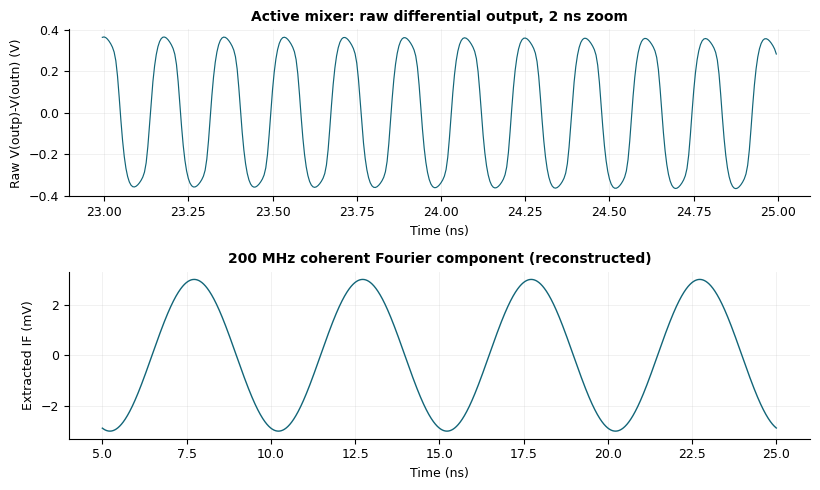

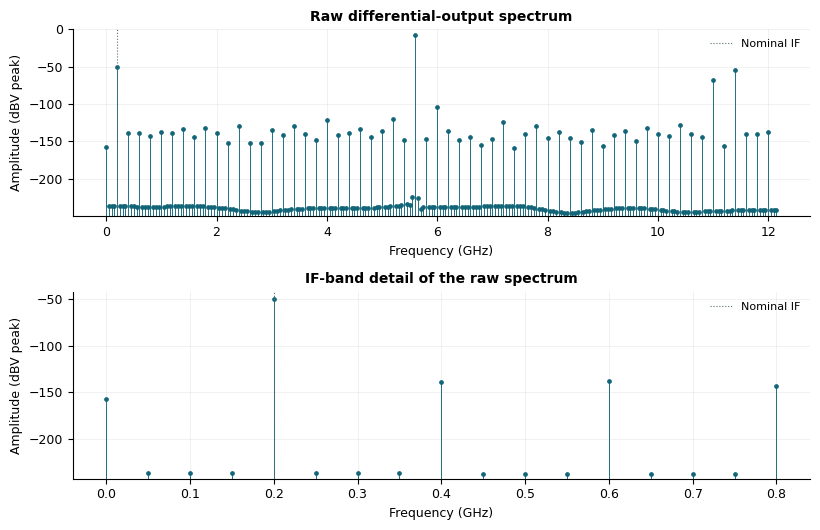

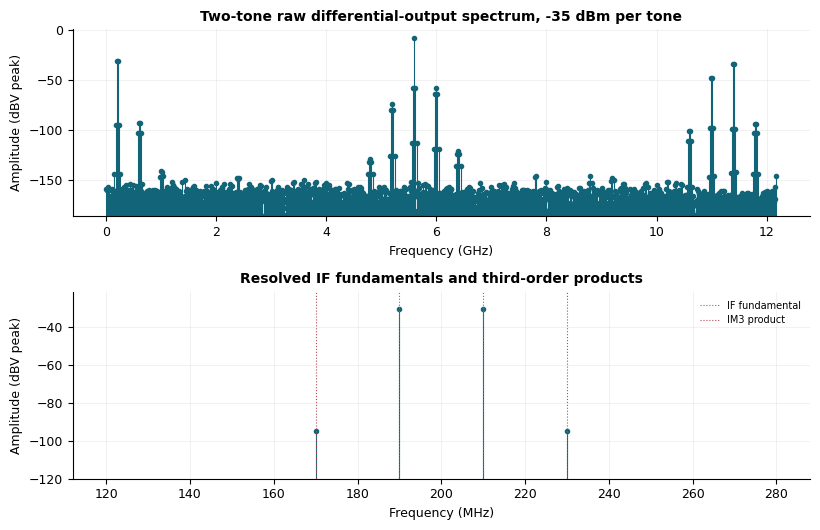

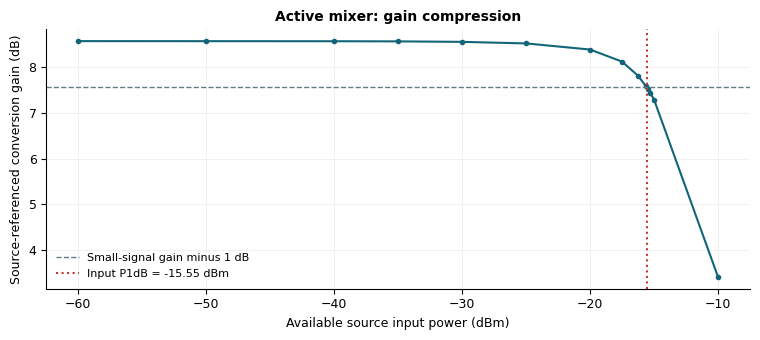

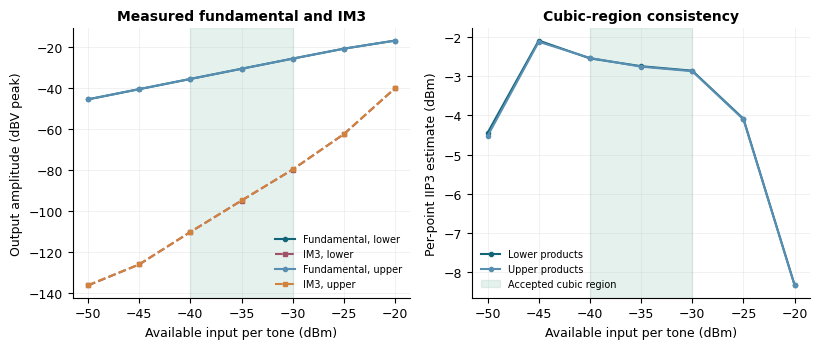

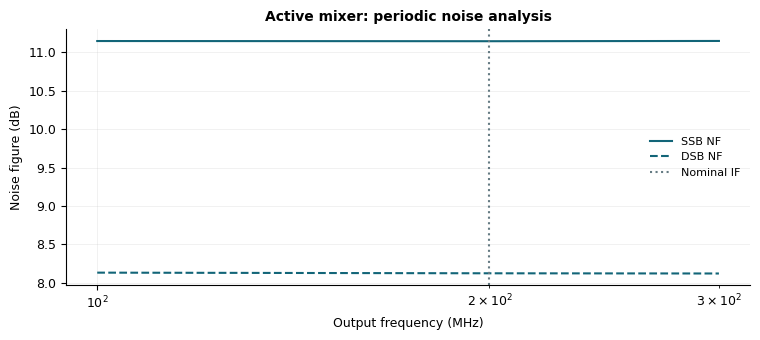

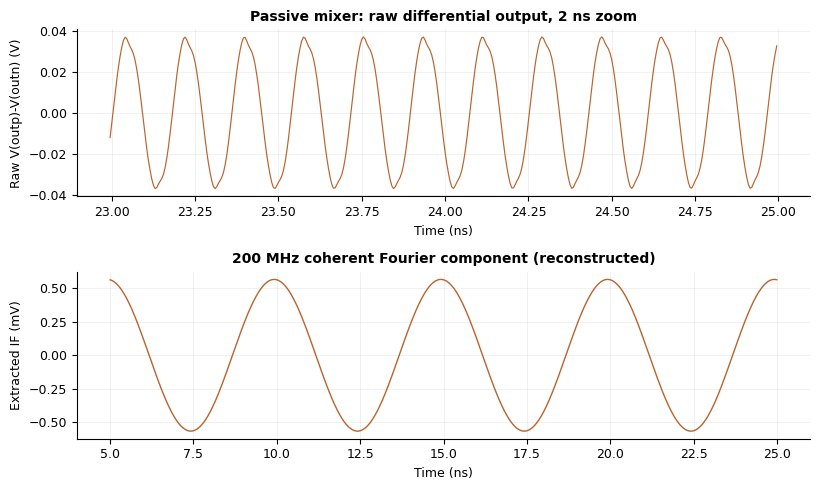

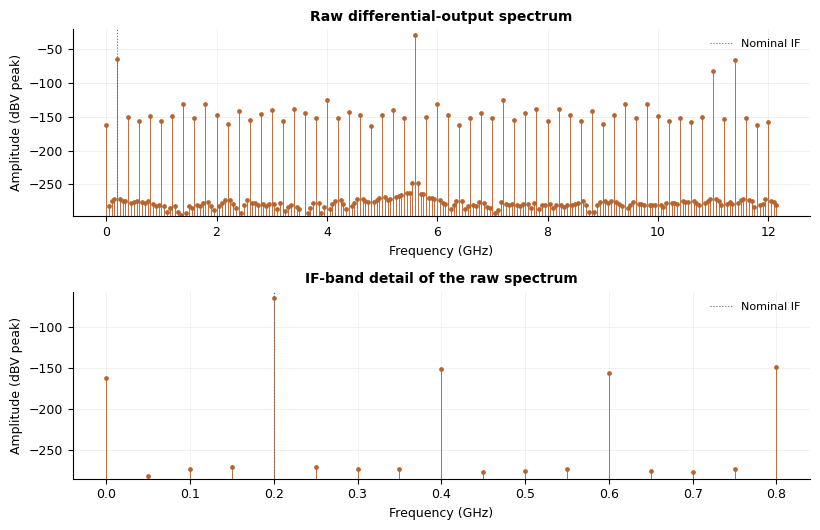

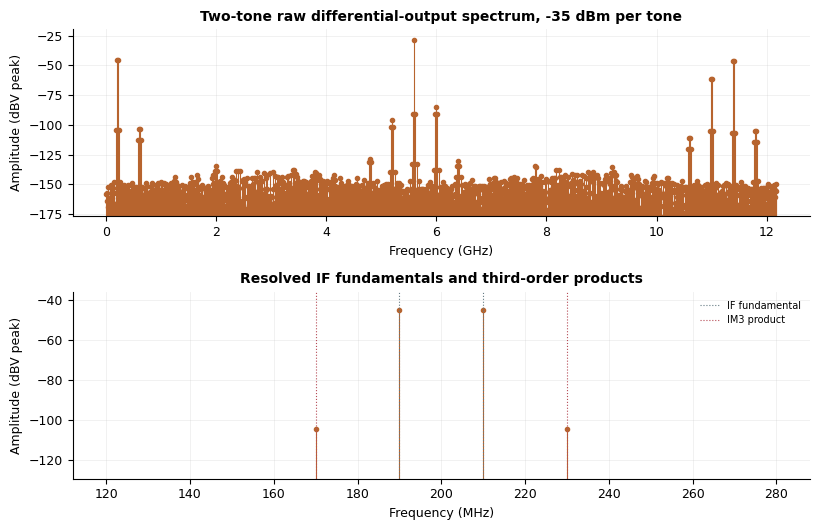

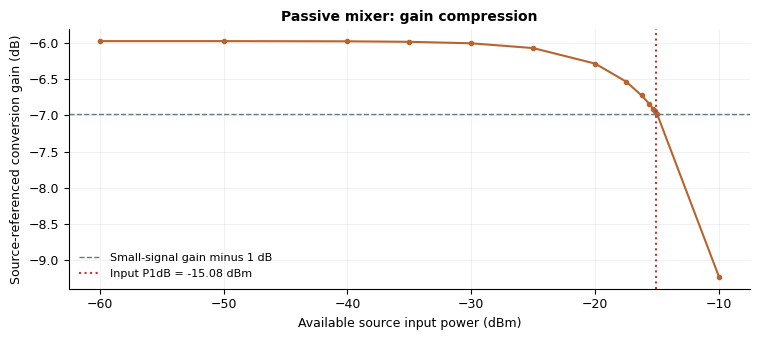

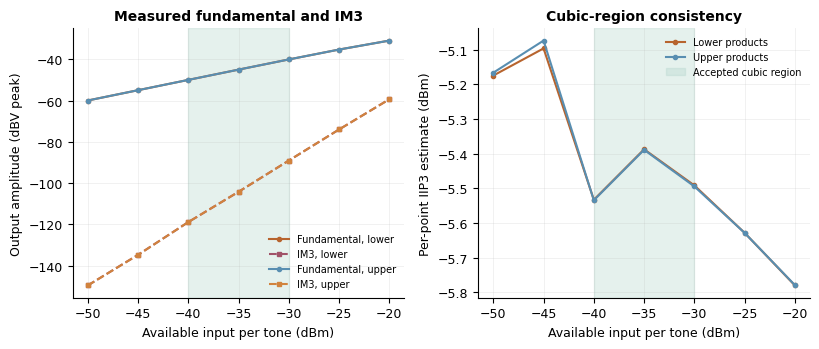

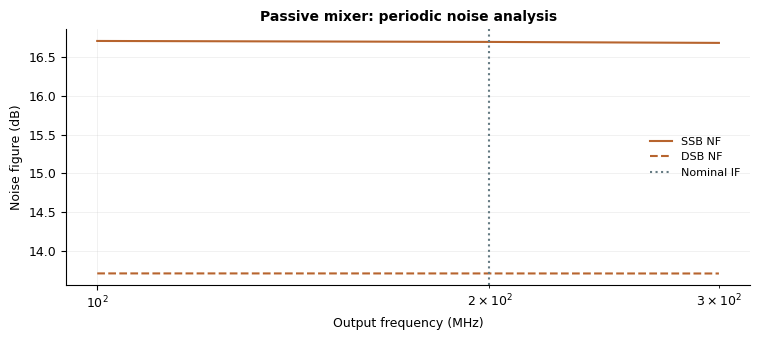

In [6]:
from plots import plot_results
import matplotlib.pyplot as plt
PLOT_STATUS = plot_results(CONFIG, allow_partial=ALLOW_PARTIAL)
plt.show()

## PDF and schematic handoff

The report is authored locally from verified numerical results. It records the actual device values, RF/LO definitions, differential IF output, loads, operating points, measurement settings, and comparison results. Generated Spectre netlists and raw logs remain available for checking a later Virtuoso schematic run.

In [ ]:
if BUILD_REPORT:
    baseline_report = ROOT / 'output/pdf/HW09_python_baseline_report.pdf'
    command = [sys.executable, str(ROOT / 'tools/build_report.py'), '--output', str(baseline_report)]
    if ALLOW_PARTIAL:
        command.append('--allow-partial')
    subprocess.run(command, cwd=ROOT, check=True)
    from IPython.display import FileLink, display
    display(FileLink(str(baseline_report)))
else:
    print('Standalone Python-baseline report skipped by BUILD_REPORT=False.')